# Мембрана и теплопроводность
### Общий пространственный оператор, различная динамика, подбор параметров

**Цель:** сравнить стационарные и нестационарные решения, восстановить параметры по шумным наблюдениям и подготовить обработку двух независимых экспериментальных источников.


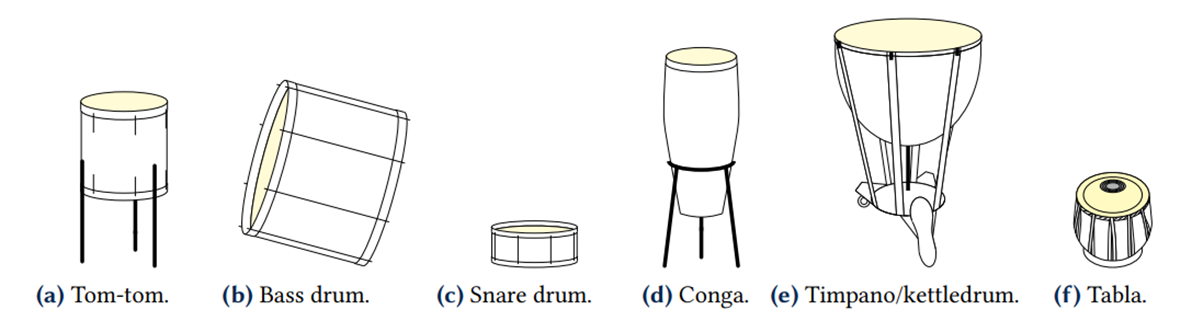

Одинаковые уравнения имеют одинаковые решения! (Р.Фейнман)

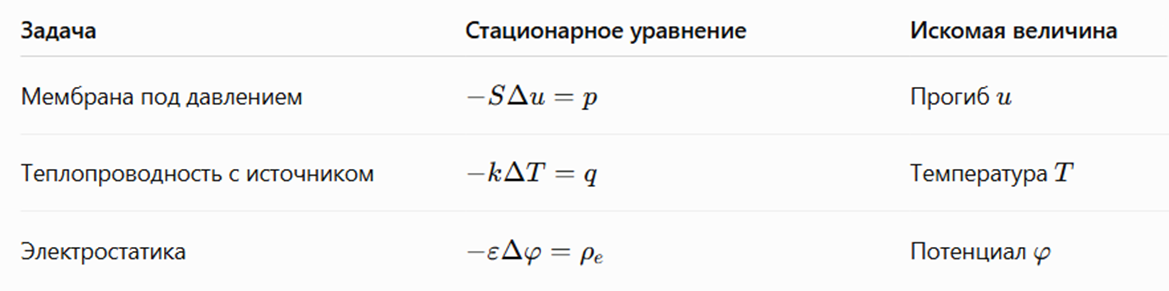

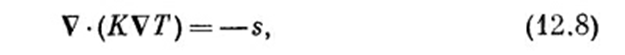
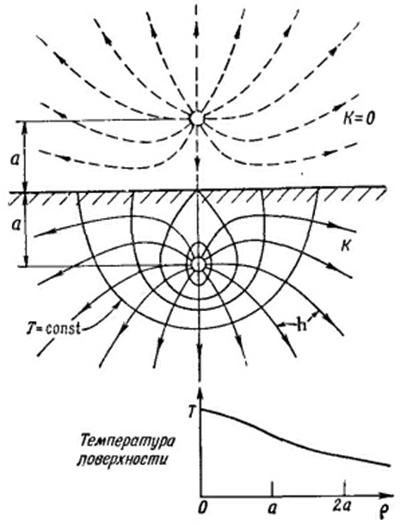

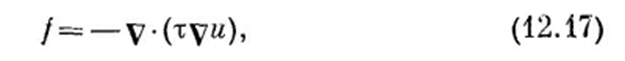
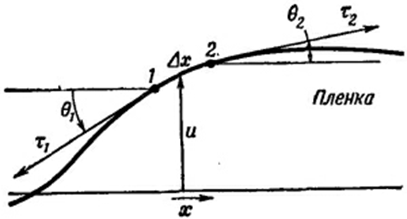
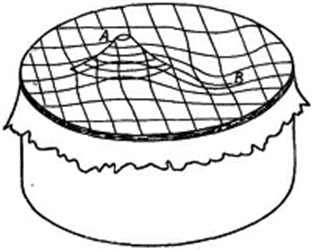

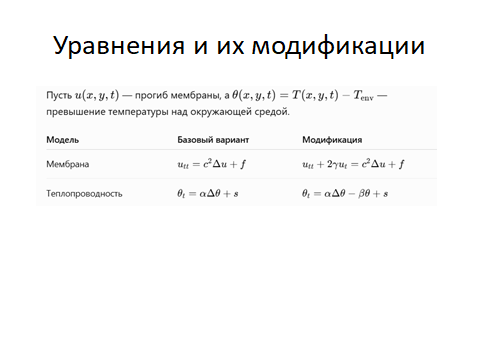

In [1]:
# Выполните эту строку один раз, если зависимости ещё не установлены:
# %pip install numpy scipy pandas matplotlib plotly networkx nbformat ipykernel

In [1]:
from pathlib import Path
import importlib
import json
import sys
import unittest
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, Markdown
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import spsolve
from scipy.linalg import eigh_tridiagonal
from scipy.signal import periodogram, spectrogram
import sympy as sp

import models
import fitting
import data_io
for module in (models, fitting, data_io):
    importlib.reload(module)

from models import RectModes, solve_membrane, solve_heat, reconstruct
from fitting import fit_membrane, fit_heat, metrics
from data_io import SOURCES, download, sha256, read_timeseries_csv

print('models:', models.__file__)
assert hasattr(models, 'RectModes'), 'Проверьте путь к models.py и перезапустите ядро.'

pio.renderers.default = 'plotly_mimetype'
pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2})
SEED = 42
RESULTS = []
DATA_DIR = Path('data')
print('Импорты выполнены. Случайное зерно:', SEED)

models: d:\user\docs\Учеба МФТИ\11 семестр\Intelligent data analysis\Lab_membrane and temperature dissipation\models.py
Импорты выполнены. Случайное зерно: 42


In [2]:
from equation_graphs import (
    equation_graph, graph_data, evaluate_graph, graph_positions,
)

OUT = Path('outputs/equation_graphs')
OUT.mkdir(parents=True, exist_ok=True)
graphs = {kind: equation_graph(kind) for kind in ('membrane', 'heat')}

In [4]:
import subprocess
check = subprocess.run(
    [sys.executable, '-m', 'unittest', '-v', 'test_equation_graphs'],
    capture_output=True, text=True,
)
print(check.stdout + check.stderr)
check.check_returncode()

test_heat_polynomial_in_1d_and_2d (test_equation_graphs.TestEquationGraphs.test_heat_polynomial_in_1d_and_2d) ... ok
test_matrix_and_dictionary (test_equation_graphs.TestEquationGraphs.test_matrix_and_dictionary) ... ok
test_membrane_polynomial (test_equation_graphs.TestEquationGraphs.test_membrane_polynomial) ... ok
test_mode_matches_solver_equations (test_equation_graphs.TestEquationGraphs.test_mode_matches_solver_equations) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.442s

OK



## 1. Постановка и источники

Для прогиба $u$ и превышения температуры $\theta=T-T_{\rm env}$:

$$u_{tt}+2\gamma u_t=c^2\Delta u+f,\qquad
\theta_t=\alpha\Delta\theta-\beta\theta+s.$$

Базовые модели: $\gamma=0$ и $\beta=0$. $c>0$ — скорость волны, $\alpha>0$ — температуропроводность; $\gamma,\beta\ge0$ — коэффициенты потерь. В опытах Б и В источники отключены: $f=s=0$.


**Теория и статьи**

1. [Фейнман, том II, глава 12: Electrostatic Analogs](https://www.feynmanlectures.caltech.edu/II_12.html). [Русский перевод: мембрана](https://www.all-fizika.com/article/index.php?id_article=832); [теплопроводность](https://www.all-fizika.com/article/index.php?id_article=684).
2. Wijnand et al. *Experimental implementation of a finite-time controller for the axisymmetric vibration modes of a tom-tom drum*. JTCAM, 2026. [DOI: 10.46298/jtcam.13030](https://doi.org/10.46298/jtcam.13030). [Ранняя конференционная версия с уравнениями, 2023](https://dael.euracoustics.org/confs/fa2023/data/articles/000602.pdf).
3. Tomanek, Stutts. *Material thermal properties estimation via a one-dimensional transient convection model*. Applied Thermal Engineering 184, 116362, 2021. [DOI](https://doi.org/10.1016/j.applthermaleng.2020.116362).
4. Tomanek, Stutts. *Data on the Validation…*. Data in Brief 40, 107632, 2022. [DOI](https://doi.org/10.1016/j.dib.2021.107632).

**Два независимых источника измерений**

- [Мембрана: Zenodo, 10.5281/zenodo.22344228](https://zenodo.org/records/22344228). [ZIP по HTTPS, около 281 МБ](https://zenodo.org/records/22344228/files/jtcam-data-13030.zip?download=1). Внутри MAT/TXT/WAV и авторский скрипт.
- [Тепловые измерения: Mendeley Data, 10.17632/sbcf36976g.1](https://data.mendeley.com/datasets/sbcf36976g/1). Прямой адрес выбранного файла нужно получить через Download.

В этой работе модели из статей упрощаются: управление барабаном не воспроизводится, акустический сигнал описывается эффективной затухающей гармоникой; для стержня используется постоянный торцевой поток и боковая теплоотдача. Применимость допущений проверяется по описанию выбранного опыта и остаткам.

In [5]:
# Аналитические поля; время не входит в пространственный лапласиан.
x, y, t = sp.symbols('x y t', real=True)
c, alpha = sp.symbols('c alpha', positive=True)
gamma, beta = sp.symbols('gamma beta', nonnegative=True)
u = sp.Function('u')(x, y, t)
theta = sp.Function('theta')(x, y, t)

Fm = evaluate_graph(graphs['membrane'], dict(u=u, c=c, gamma=gamma), (x, y), t)
Fh = evaluate_graph(graphs['heat'], dict(theta=theta, alpha=alpha, beta=beta), (x, y), t)
display(sp.Eq(sp.diff(u, t, 2), Fm))
display(sp.Eq(sp.diff(theta, t), Fh))
display(sp.Eq(sp.diff(u, t, 2), Fm.subs(gamma, 0)))
display(sp.Eq(sp.diff(theta, t), Fh.subs(beta, 0)))

# Порядок параметров одинаков в графе, таблице и численном интерфейсе.
p_membrane = np.array([1.0, 0.15])  # c, gamma
p_heat = np.array([0.05, 0.10])     # alpha, beta
print('Безразмерные тестовые значения:', p_membrane, p_heat)


Eq(Derivative(u(x, y, t), (t, 2)), c**2*(Derivative(u(x, y, t), (x, 2)) + Derivative(u(x, y, t), (y, 2))) - 2*gamma*Derivative(u(x, y, t), t))

Eq(Derivative(theta(x, y, t), t), alpha*(Derivative(theta(x, y, t), (x, 2)) + Derivative(theta(x, y, t), (y, 2))) - beta*theta(x, y, t))

Eq(Derivative(u(x, y, t), (t, 2)), c**2*(Derivative(u(x, y, t), (x, 2)) + Derivative(u(x, y, t), (y, 2))))

Eq(Derivative(theta(x, y, t), t), alpha*(Derivative(theta(x, y, t), (x, 2)) + Derivative(theta(x, y, t), (y, 2))))

Безразмерные тестовые значения: [1.   0.15] [0.05 0.1 ]


membrane: 10 вершин, 10 рёбер


,label,op,args,shape,value
u,u,input,[],scalar_field,NaN
c,c,input,[],scalar,NaN
gamma,γ,input,[],scalar,NaN
two,2,constant,[],scalar,2.0
lap,Δu,laplacian,[u],scalar_field,NaN
ut,∂ₜu,dt,[u],scalar_field,NaN
c2,c²,square,[c],scalar,NaN
loss,2γ∂ₜu,multiply,"[two, gamma, ut]",scalar_field,NaN
elastic,c²Δu,multiply,"[c2, lap]",scalar_field,NaN
rhs,F = ∂ₜₜu,subtract,"[elastic, loss]",scalar_field,NaN


,u,c,gamma,two,lap,ut,c2,loss,elastic,rhs
u,0,0,0,0,0,0,0,0,0,0
c,0,0,0,0,0,0,0,0,0,0
gamma,0,0,0,0,0,0,0,0,0,0
two,0,0,0,0,0,0,0,0,0,0
lap,1,0,0,0,0,0,0,0,0,0
ut,1,0,0,0,0,0,0,0,0,0
c2,0,1,0,0,0,0,0,0,0,0
loss,0,0,1,1,0,1,0,0,0,0
elastic,0,0,0,0,1,0,1,0,0,0
rhs,0,0,0,0,0,0,0,1,1,0


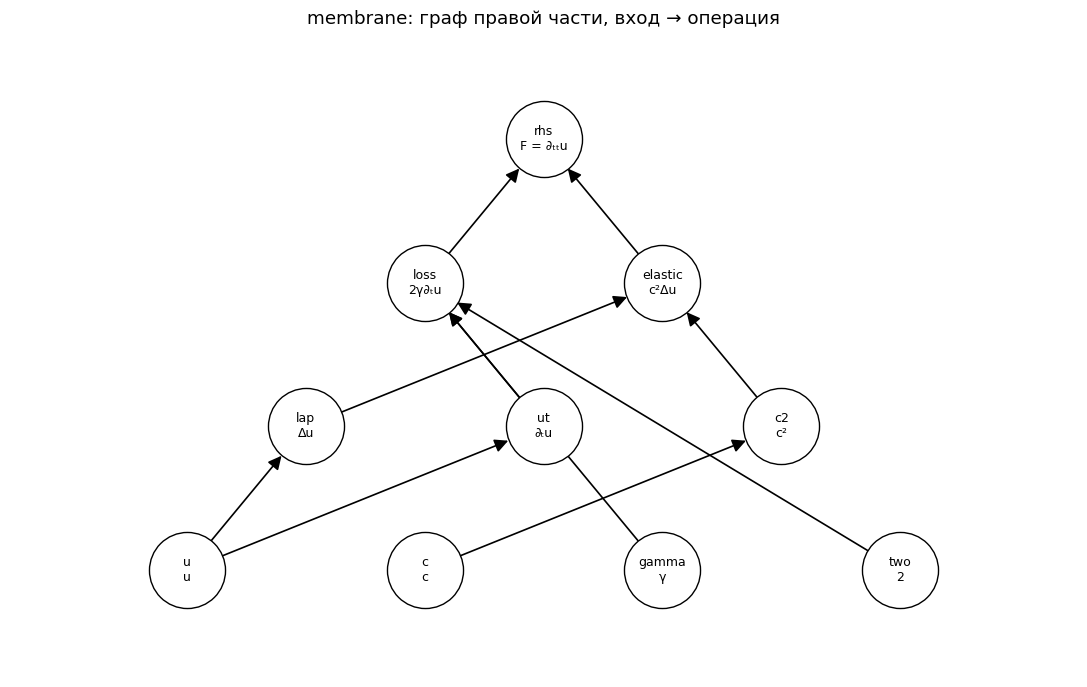

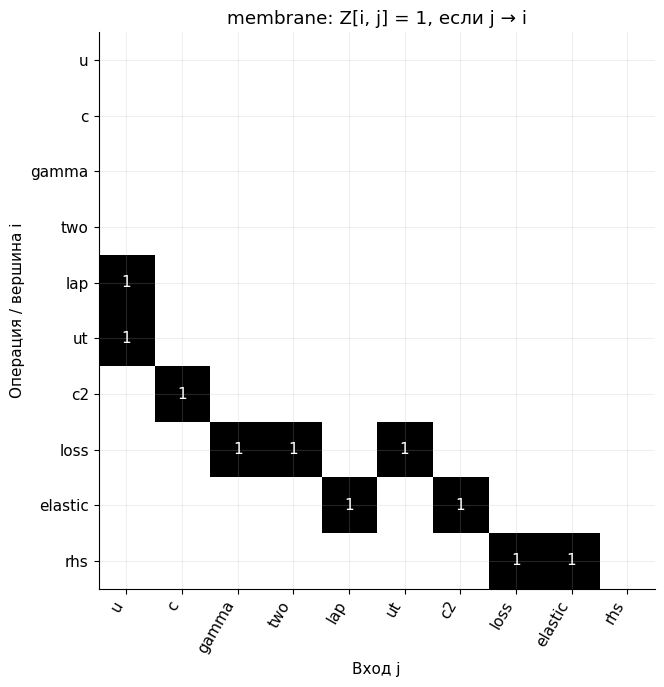

heat: 7 вершин, 7 рёбер


,label,op,args,shape
theta,θ,input,[],scalar_field
alpha,α,input,[],scalar
beta,β,input,[],scalar
lap,Δθ,laplacian,[theta],scalar_field
loss,βθ,multiply,"[beta, theta]",scalar_field
diffusion,αΔθ,multiply,"[alpha, lap]",scalar_field
rhs,F = ∂ₜθ,subtract,"[diffusion, loss]",scalar_field


,theta,alpha,beta,lap,loss,diffusion,rhs
theta,0,0,0,0,0,0,0
alpha,0,0,0,0,0,0,0
beta,0,0,0,0,0,0,0
lap,1,0,0,0,0,0,0
loss,1,0,1,0,0,0,0
diffusion,0,1,0,1,0,0,0
rhs,0,0,0,0,1,1,0


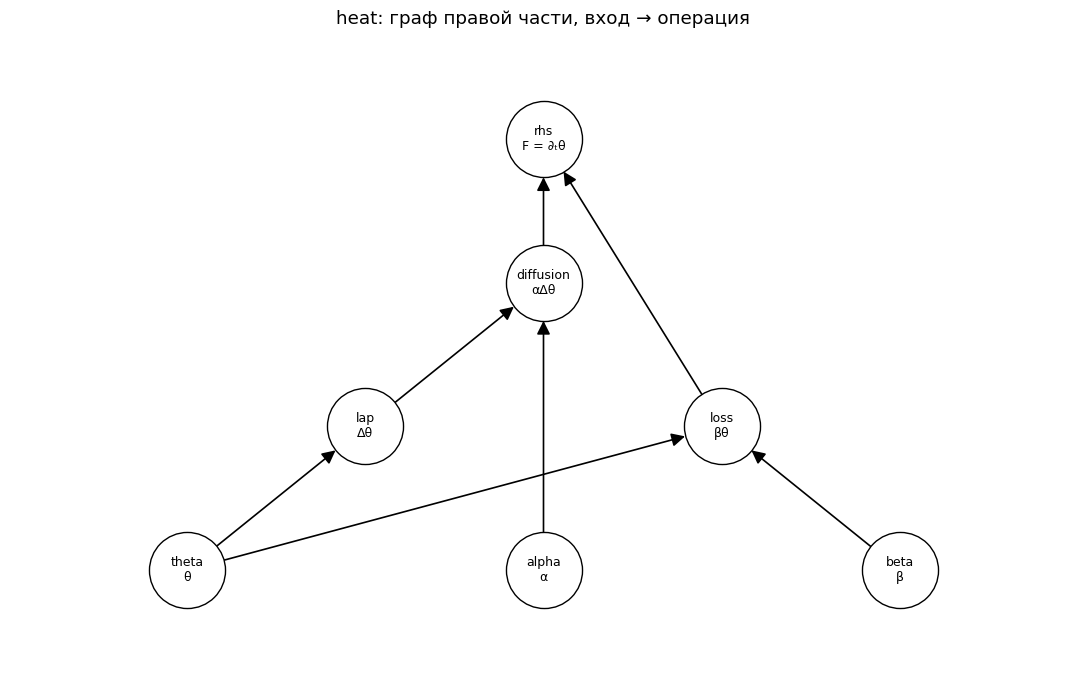

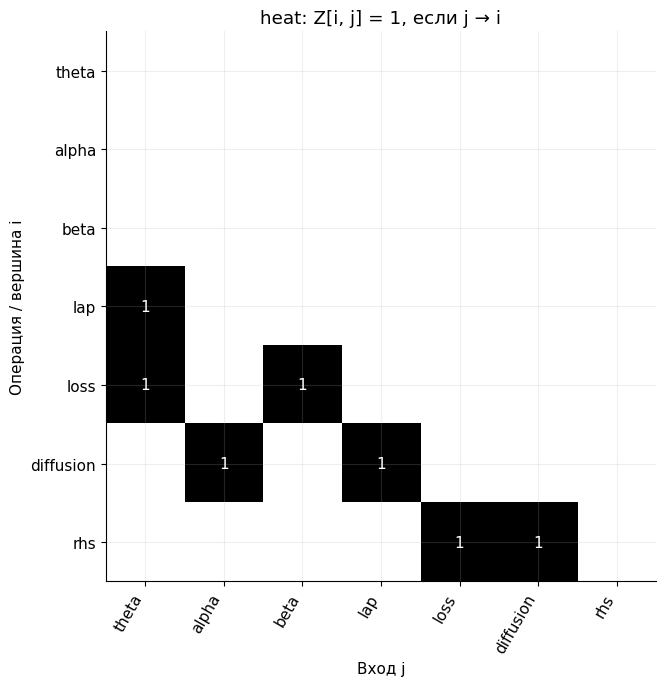

In [6]:
for kind, graph in graphs.items():
    data, Z = graph_data(graph)
    order = data['order']
    print(f'{kind}: {len(graph)} вершин, {graph.number_of_edges()} рёбер')
    display(pd.DataFrame.from_dict(data['nodes'], orient='index'))
    display(pd.DataFrame(Z, index=order, columns=order))

    fig, ax = plt.subplots(figsize=(11, 7))
    labels = {n: f"{n}\n{graph.nodes[n]['label']}" for n in graph}
    nx.draw_networkx(
        graph, pos=graph_positions(graph), labels=labels, ax=ax,
        node_color='white', edgecolors='black', node_size=3000,
        font_size=9, arrows=True, arrowsize=20,
        edge_color='black', width=1.2,
    )
    ax.set_title(f'{kind}: граф правой части, вход → операция')
    ax.margins(0.18)
    ax.set_axis_off()
    fig.tight_layout()
    fig.savefig(OUT / f'{kind}_graph.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.imshow(Z, cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
    ax.set_xticks(range(len(order)), order, rotation=60, ha='right')
    ax.set_yticks(range(len(order)), order)
    for i, j in np.argwhere(Z == 1):
        ax.text(j, i, '1', ha='center', va='center', color='white')
    ax.set(xlabel='Вход j', ylabel='Операция / вершина i',
           title=f'{kind}: Z[i, j] = 1, если j → i')
    fig.tight_layout()
    fig.savefig(OUT / f'{kind}_adjacency.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    # Сохраняем смысл узлов и порядок аргументов вместе с матрицей.
    (OUT / f'{kind}_graph.json').write_text(
        json.dumps(data, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    pd.DataFrame(Z, index=order, columns=order).to_csv(
        OUT / f'{kind}_adjacency.csv', encoding='utf-8'
    )

## 2. Параметры и начальные условия демонстрационного опыта

Область $[0,1]^2$, на границе $u=\theta=0$. Начальные поля:
$$u(x,y,0)=\theta(x,y,0)=\sin(\pi x)\sin(\pi y)+0.3\sin(2\pi x)\sin(\pi y),\quad u_t(x,y,0)=0.$$

Значения ниже **безразмерные, выбранные для теста**, не измерены в статьях. Для физических единиц нужно согласованно задать длину и время, а также изменить границы поиска параметров.

Моды $\phi_{mn}=\sin(m\pi x)\sin(n\pi y)$ имеют собственные значения $\lambda_{mn}=\pi^2(m^2+n^2)$. Модальные уравнения:
$$\ddot a+2\gamma\dot a+c^2\lambda a=0,\qquad \dot b+(\alpha\lambda+\beta)b=0.$$

Начальные условия в программном интерфейсе относятся к первому элементу массива времени. Для прогноза на тестовом интервале решаем задачу **от исходного начального момента**, затем выбираем нужные строки.

In [7]:
modes = RectModes(modes=((1, 1), (2, 1)))
initial = np.array([1.0, 0.3])
truth_m = {'c': 1.0, 'gamma': 0.15}
truth_h = {'alpha': 0.05, 'beta': 0.10}
parameters = pd.DataFrame({
    'Параметр': ['c', 'gamma', 'alpha', 'beta'],
    'Тестовая истина': [1.0, 0.15, 0.05, 0.10],
    'Начальная оценка': [0.8, 0.05, 0.03, 0.02],
    'Нижняя граница': [0.2, 0, 0.005, 0],
    'Верхняя граница': [2.0, 1.0, 0.2, 0.5],
})
display(parameters)

,Параметр,Тестовая истина,Начальная оценка,Нижняя граница,Верхняя граница
0,c,1.00,0.80,0.200,2.0
1,gamma,0.15,0.05,0.000,1.0
2,alpha,0.05,0.03,0.005,0.2
3,beta,0.10,0.02,0.000,0.5


## А. Стационарная аналогия и независимая проверка сетки

Берём $g=2\pi^2\sin(\pi x)\sin(\pi y)$. Точное нормированное решение $w=\sin(\pi x)\sin(\pi y)$.

Пятидиагональная разностная аппроксимация $-\Delta$ с нулевой границей решается через `spsolve`. Три физические задачи после нормировки приводят к **одной** системе. Их совпадение заложено постановкой; независимая численная проверка — сравнение с аналитическим решением и уменьшение ошибки при сгущении сетки.

,n,dx,max_error,observed_order
0,15,0.062500,0.003219,NaN
1,31,0.031250,0.000804,2.002087
2,63,0.015625,0.000201,2.000522


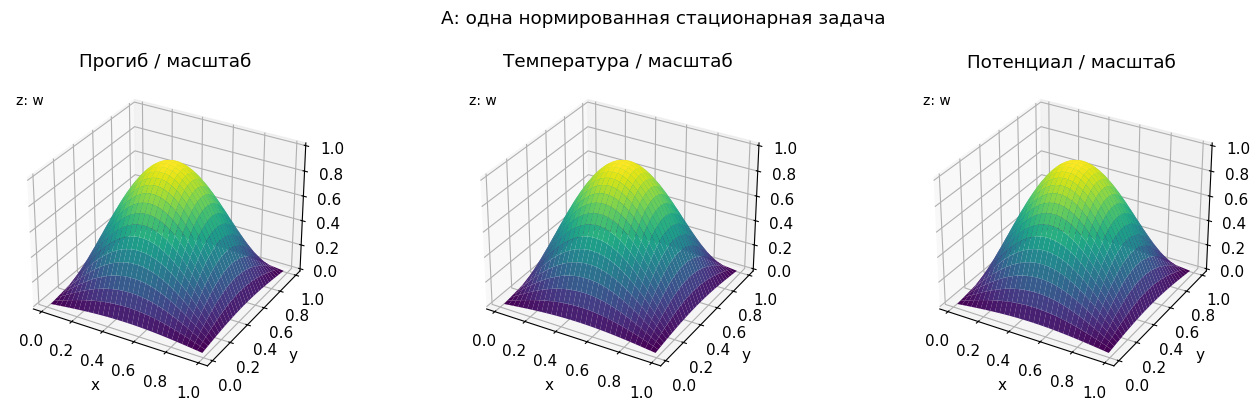

In [8]:
convergence = []
for n in (15, 31, 63):
    dx = 1.0 / (n + 1)
    line = np.arange(1, n + 1) * dx
    XA, YA = np.meshgrid(line, line)
    exact = np.sin(np.pi * XA) * np.sin(np.pi * YA)
    D = diags([-np.ones(n-1), 2*np.ones(n), -np.ones(n-1)], [-1, 0, 1]) / dx**2
    L = kron(eye(n), D) + kron(D, eye(n))
    numerical = spsolve(L.tocsr(), (2*np.pi**2*exact).ravel()).reshape(n, n)
    convergence.append({'n': n, 'dx': dx, 'max_error': np.max(np.abs(numerical-exact))})
convergence = pd.DataFrame(convergence)
convergence['observed_order'] = np.r_[np.nan,
    np.log(convergence.max_error.to_numpy()[:-1] / convergence.max_error.to_numpy()[1:])
    / np.log(convergence.dx.to_numpy()[:-1] / convergence.dx.to_numpy()[1:])]
display(convergence)
fig = plt.figure(figsize=(15, 4))
for i, title in enumerate(['Прогиб / масштаб', 'Температура / масштаб', 'Потенциал / масштаб']):
    ax = fig.add_subplot(1, 3, i+1, projection='3d')
    ax.plot_surface(XA, YA, numerical, cmap='viridis', linewidth=0)
    ax.set(xlabel='x', ylabel='y', zlabel='w', title=title)
fig.suptitle('А: одна нормированная стационарная задача')
for panel in fig.axes:
    if hasattr(panel, "zaxis"):
        zlabel = panel.get_zlabel()
        panel.set_zlabel("")
        panel.text2D(0.02, 0.94, 'z: '+zlabel, transform=panel.transAxes,
                     rotation=0, va="top", fontsize=10)
plt.tight_layout(rect=(0,0,0.94,1))
plt.show()

## Б. Колебания и охлаждение

Сравним модели без потерь и с потерями. У мембраны затухает механическая энергия. У тепловой задачи убывает норма поля (она не равна полной тепловой энергии). Скорость охлаждения высоких пространственных мод больше.

Численный солвер — `solve_ivp(method="DOP853")` в модальной системе. Пространственная сетка нужна только для восстановления и отображения поля.

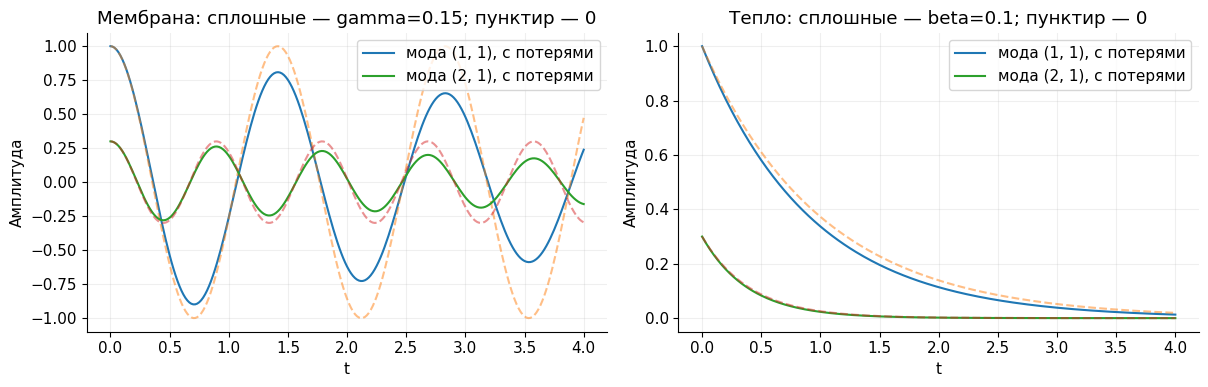

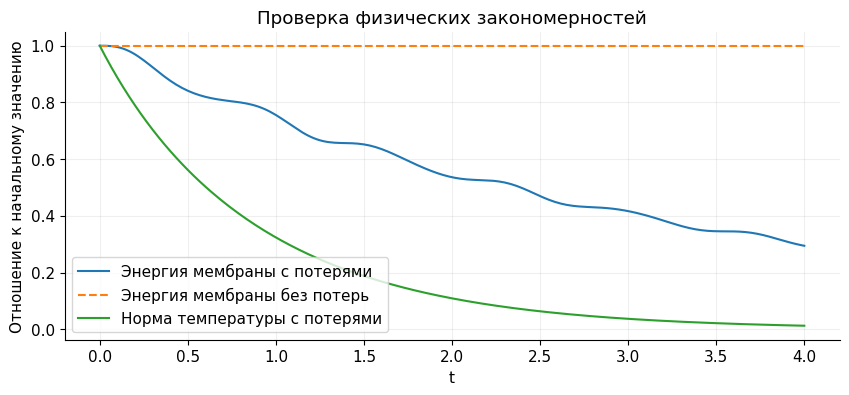

In [9]:
times = np.linspace(0, 4, 241)
a0, v0 = solve_membrane(times, modes, initial, c=1.0, gamma=0)
a, v = solve_membrane(times, modes, initial, **truth_m)
b0 = solve_heat(times, modes, initial, alpha=0.05, beta=0)
b = solve_heat(times, modes, initial, **truth_h)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for j, name in enumerate(modes.modes):
    axes[0].plot(times, a[:, j], label=f'мода {name}, с потерями')
    axes[0].plot(times, a0[:, j], '--', alpha=0.5)
    axes[1].plot(times, b[:, j], label=f'мода {name}, с потерями')
    axes[1].plot(times, b0[:, j], '--', alpha=0.5)
axes[0].set(title='Мембрана: сплошные — gamma=0.15; пунктир — 0', xlabel='t', ylabel='Амплитуда')
axes[1].set(title='Тепло: сплошные — beta=0.1; пунктир — 0', xlabel='t', ylabel='Амплитуда')
for ax in axes:
    ax.legend()
for panel in fig.axes:
    if hasattr(panel, "zaxis"):
        zlabel = panel.get_zlabel()
        panel.set_zlabel("")
        panel.text2D(0.02, 0.94, 'z: '+zlabel, transform=panel.transAxes,
                     rotation=0, va="top", fontsize=10)
plt.tight_layout(rect=(0,0,0.94,1))
plt.show()
E = 0.5*np.sum(v**2 + truth_m['c']**2*modes.eigenvalues*a**2, axis=1)
E0 = 0.5*np.sum(v0**2 + modes.eigenvalues*a0**2, axis=1)
heat_norm = np.sqrt(np.sum(b**2, axis=1))
fig, ax = plt.subplots()
ax.plot(times, E/E[0], label='Энергия мембраны с потерями')
ax.plot(times, E0/E0[0], '--', label='Энергия мембраны без потерь')
ax.plot(times, heat_norm/heat_norm[0], label='Норма температуры с потерями')
ax.set(xlabel='t', ylabel='Отношение к начальному значению', title='Проверка физических закономерностей')
ax.legend()
plt.show()

In [10]:
line = np.linspace(0, 1, 41)
X, Y = np.meshgrid(line, line)
grid_points = np.column_stack((X.ravel(), Y.ravel()))
U = reconstruct(a, modes, grid_points).reshape(len(times), *X.shape)
T = reconstruct(b, modes, grid_points).reshape(len(times), *X.shape)
fig = make_subplots(rows=1, cols=2, specs=[[{'type':'surface'}, {'type':'surface'}]],
                    subplot_titles=['Мембрана u(x,y,t)', 'Температура theta(x,y,t)'])
fig.add_trace(go.Surface(x=X, y=Y, z=U[0], colorscale='RdBu', cmin=-1.3, cmax=1.3,
                        showscale=False), row=1, col=1)
fig.add_trace(go.Surface(x=X, y=Y, z=T[0], colorscale='Inferno', cmin=0, cmax=1.3,
                        showscale=False), row=1, col=2)
frames = []
for j in range(0, len(times), 4):
    frames.append(go.Frame(name=str(j), data=[go.Surface(z=U[j]), go.Surface(z=T[j])], traces=[0,1]))
fig.frames = frames
steps = [dict(method='animate', label=f'{times[int(frame.name)]:.2f}',
              args=[[frame.name], dict(mode='immediate', frame=dict(duration=0, redraw=True),
                                     transition=dict(duration=0))]) for frame in frames]
fig.update_layout(height=530, title='Б: одинаковое начальное поле, разная динамика',
    scene=dict(xaxis_title='x', yaxis_title='y', zaxis=dict(title='u', range=[-1.3,1.3])),
    scene2=dict(xaxis_title='x', yaxis_title='y', zaxis=dict(title='theta', range=[0,1.3])),
    sliders=[dict(currentvalue=dict(prefix='t = '), steps=steps)],
    updatemenus=[dict(type='buttons', buttons=[
        dict(label='▶', method='animate', args=[None, dict(frame=dict(duration=70, redraw=True), fromcurrent=True)]),
        dict(label='Пауза', method='animate', args=[[None], dict(mode='immediate', frame=dict(duration=0))])])])
fig.show()

В анимации оси — `x, y, значение поля`, время задаётся ползунком. Следующий рисунок явно включает время в одну из трёх осей: сечение при `y=0.5`. Это 2D-пространственная задача, а не уравнение в трёх пространственных измерениях.

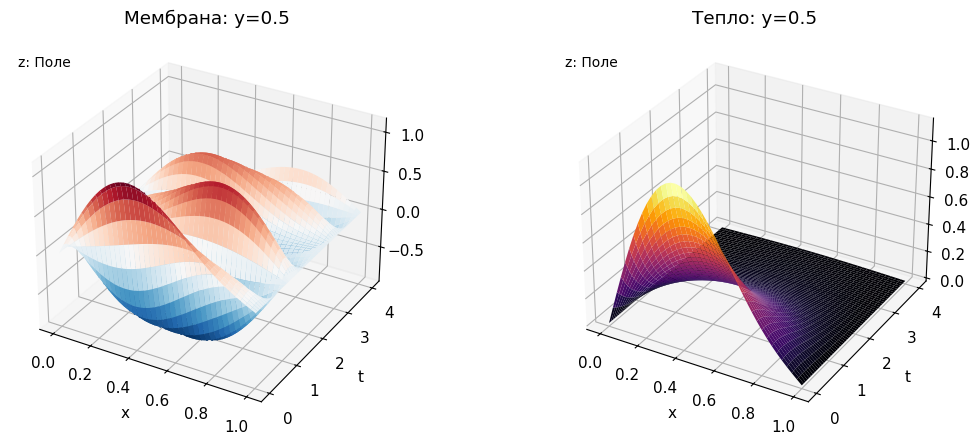

In [11]:
section_points = np.column_stack((line, np.full_like(line, 0.5)))
section_u = reconstruct(a, modes, section_points)
section_t = reconstruct(b, modes, section_points)
XS, TS = np.meshgrid(line, times)
fig = plt.figure(figsize=(13, 4.5))
for idx, (field, title, cmap) in enumerate([(section_u, 'Мембрана: y=0.5', 'RdBu_r'),
                                          (section_t, 'Тепло: y=0.5', 'inferno')]):
    ax = fig.add_subplot(1, 2, idx+1, projection='3d')
    ax.plot_surface(XS, TS, field, cmap=cmap, linewidth=0, rcount=70, ccount=41)
    ax.set(xlabel='x', ylabel='t', zlabel='Поле', title=title)
for panel in fig.axes:
    if hasattr(panel, "zaxis"):
        zlabel = panel.get_zlabel()
        panel.set_zlabel("")
        panel.text2D(0.02, 0.94, 'z: '+zlabel, transform=panel.transAxes,
                     rotation=0, va="top", fontsize=10)
plt.tight_layout(rect=(0,0,0.94,1))
plt.show()

## В. Обучение физических моделей на синтетических наблюдениях

Наблюдения генерируются **аналитически**, подбор параметров вызывает численный солвер. Добавляем гауссов шум со стандартным отклонением 1% или 5% от максимума абсолютного чистого сигнала. Это не реальные измерения.

Первые 70% временных точек — обучение, последние 30% — тест. Два датчика видят обе моды. Для тепла одна наблюдаемая мода определяла бы только сумму $\alpha\lambda+\beta$.

Оптимизатор модифицированной модели — `least_squares(method='trf')`. Базовая модель также калибруется, но по одномерной сетке значений $c$ или $\alpha$ при строго нулевых потерях. Ошибка сеточного поиска означает, что такое сравнение имеет конечное разрешение (120 кандидатов). Для ускорения базового поиска используем точные модальные решения.

In [13]:
t_fit = np.linspace(0, 4, 181)
sensors = np.array([[0.25, 0.5], [0.65, 0.5]])
cut = int(0.7*len(t_fit))
tr = slice(0, cut)
te = slice(cut, None)
omega = np.sqrt(truth_m['c']**2*modes.eigenvalues - truth_m['gamma']**2)
analytic_m = initial*np.exp(-truth_m['gamma']*t_fit[:,None])*(
    np.cos(t_fit[:,None]*omega) + truth_m['gamma']/omega*np.sin(t_fit[:,None]*omega))
analytic_h = initial*np.exp(-t_fit[:,None]*(truth_h['alpha']*modes.eigenvalues+truth_h['beta']))
clean_data = {'membrane': reconstruct(analytic_m, modes, sensors),
              'heat': reconstruct(analytic_h, modes, sensors)}
fit_records = []
parameter_records = []
fit_cache = {}
for case_id, (kind, clean) in enumerate(clean_data.items()):
    truth = truth_m if kind == 'membrane' else truth_h
    for noise_fraction in (0.01, 0.05):
        rng = np.random.default_rng(SEED + case_id)
        sigma = noise_fraction*np.max(np.abs(clean))
        observed = clean + rng.normal(0, sigma, clean.shape)
        if kind == 'membrane':
            fit = fit_membrane(t_fit[tr], observed[tr], sensors, modes, initial)
            mod, _ = solve_membrane(t_fit, modes, initial, **fit.parameters)
            candidates = np.linspace(0.2, 2.0, 120)
        else:
            fit = fit_heat(t_fit[tr], observed[tr], sensors, modes, initial)
            mod = solve_heat(t_fit, modes, initial, **fit.parameters)
            candidates = np.linspace(0.005, 0.2, 120)
        prediction = reconstruct(mod, modes, sensors)
        best_loss = np.inf
        for candidate in candidates:
            if kind == 'membrane':
                modal_base = initial*np.cos(t_fit[:,None]*candidate*np.sqrt(modes.eigenvalues))
            else:
                modal_base = initial*np.exp(-t_fit[:,None]*candidate*modes.eigenvalues)
            trial = reconstruct(modal_base, modes, sensors)
            loss = np.mean((trial[tr]-observed[tr])**2)
            if loss < best_loss:
                best_loss, best_base, best_parameter = loss, trial.copy(), candidate
        for label, pred in [('без потерь', best_base), ('с потерями', prediction)]:
            fit_records.append(dict(model=kind, noise=noise_fraction, variant=label,
                train_rmse=metrics(observed[tr], pred[tr])['rmse'],
                test_rmse=metrics(observed[te], pred[te])['rmse'],
                test_mae=metrics(observed[te], pred[te])['mae'],
                test_clean_rmse=metrics(clean[te], pred[te])['rmse']))
        for name, value in fit.parameters.items():
            parameter_records.append(dict(model=kind, noise=noise_fraction, parameter=name,
                true=truth[name], estimated=value, relative_error=abs(value-truth[name])/abs(truth[name])))
        fit_cache[(kind, noise_fraction)] = dict(observed=observed, prediction=prediction,
                                               base=best_base, fit=fit, sigma=sigma)
summary = pd.DataFrame(fit_records)
parameter_summary = pd.DataFrame(parameter_records)
display(summary.round(6))
display(parameter_summary.round(6))

,model,noise,variant,train_rmse,test_rmse,test_mae,test_clean_rmse
0,membrane,0.01,без потерь,0.124656,0.257768,0.225961,0.257187
1,membrane,0.01,с потерями,0.009377,0.009795,0.007786,0.001682
2,membrane,0.05,без потерь,0.133818,0.263572,0.229970,0.257187
3,membrane,0.05,с потерями,0.046882,0.048970,0.038927,0.008392
4,heat,0.01,без потерь,0.011218,0.008834,0.007267,0.001028
5,heat,0.01,с потерями,0.010472,0.008648,0.007113,0.000213
6,heat,0.05,без потерь,0.052412,0.043236,0.035562,0.001028
7,heat,0.05,с потерями,0.052357,0.043239,0.035564,0.001062


,model,noise,parameter,true,estimated,relative_error
0,membrane,0.01,c,1.00,0.999758,0.000242
1,membrane,0.01,gamma,0.15,0.150702,0.004680
2,membrane,0.05,c,1.00,0.998782,0.001218
3,membrane,0.05,gamma,0.15,0.153502,0.023348
4,heat,0.01,alpha,0.05,0.050227,0.004532
5,heat,0.01,beta,0.10,0.098462,0.015377
6,heat,0.05,alpha,0.05,0.051229,0.024575
7,heat,0.05,beta,0.10,0.090692,0.093081


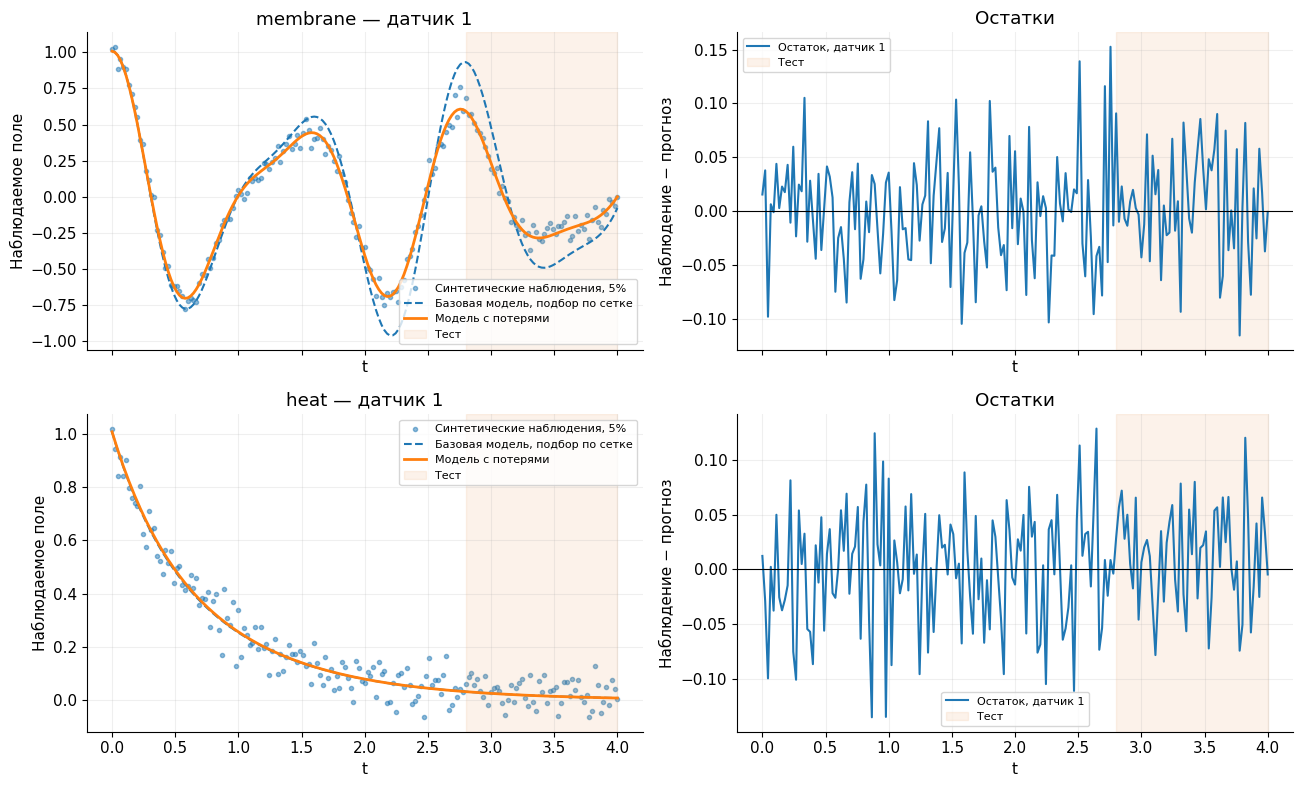

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for row, kind in enumerate(['membrane', 'heat']):
    item = fit_cache[(kind, 0.05)]
    axes[row,0].scatter(t_fit, item['observed'][:,0], s=9, alpha=0.5, label='Синтетические наблюдения, 5%')
    axes[row,0].plot(t_fit, item['base'][:,0], '--', label='Базовая модель, подбор по сетке')
    axes[row,0].plot(t_fit, item['prediction'][:,0], lw=2, label='Модель с потерями')
    axes[row,0].set(title=kind+' — датчик 1', ylabel='Наблюдаемое поле')
    residual = item['observed'] - item['prediction']
    axes[row,1].plot(t_fit, residual[:,0], label='Остаток, датчик 1')
    axes[row,1].axhline(0, color='black', lw=0.8)
    axes[row,1].set(title='Остатки', ylabel='Наблюдение − прогноз')
    for ax in axes[row]:
        ax.axvspan(t_fit[cut], t_fit[-1], color='#e89a55', alpha=0.12, label='Тест')
        ax.set_xlabel('t')
        ax.legend(fontsize=8)
for panel in fig.axes:
    if hasattr(panel, "zaxis"):
        zlabel = panel.get_zlabel()
        panel.set_zlabel("")
        panel.text2D(0.02, 0.94, 'z: '+zlabel, transform=panel.transAxes,
                     rotation=0, va="top", fontsize=10)
plt.tight_layout(rect=(0,0,0.94,1))
plt.show()

### 3D-поля после подбора параметров

Поверхность — решение с оценёнными параметрами, точки — синтетические датчики на сечении. Вне датчиков поле восстанавливается из принятого модального базиса, а не измеряется. Область теста начинается после вертикальной границы на предыдущем рисунке.

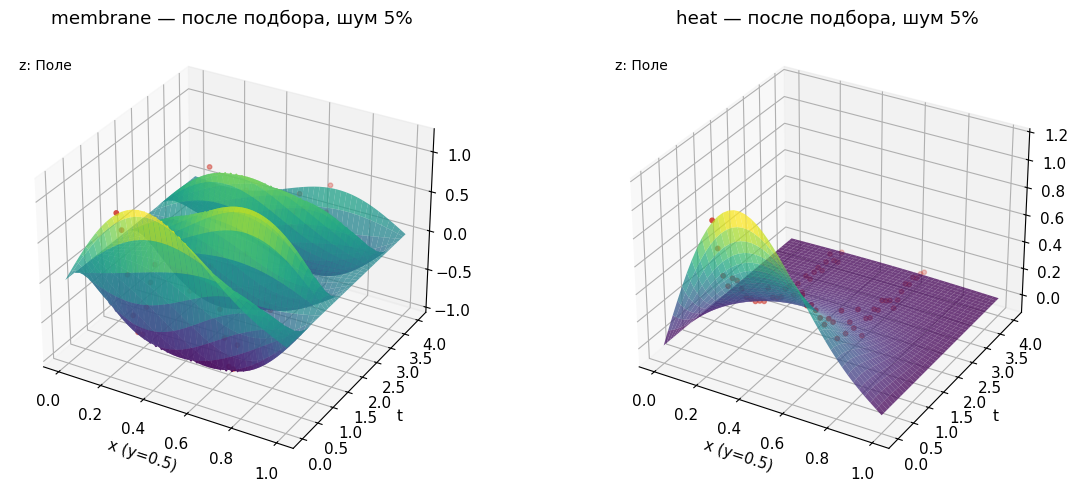

In [14]:
fig = plt.figure(figsize=(14, 5))
for index, kind in enumerate(['membrane', 'heat']):
    item = fit_cache[(kind, 0.05)]
    if kind == 'membrane':
        learned_modes, _ = solve_membrane(t_fit, modes, initial, **item['fit'].parameters)
    else:
        learned_modes = solve_heat(t_fit, modes, initial, **item['fit'].parameters)
    learned_section = reconstruct(learned_modes, modes, section_points)
    XX, TT = np.meshgrid(line, t_fit)
    ax = fig.add_subplot(1, 2, index+1, projection='3d')
    ax.plot_surface(XX, TT, learned_section, cmap='viridis', alpha=0.75, linewidth=0)
    for sensor_id, point in enumerate(sensors):
        ax.scatter(np.full(len(t_fit[::6]), point[0]), t_fit[::6],
                   item['observed'][::6,sensor_id], s=10, color='#d34d42')
    ax.set(xlabel='x (y=0.5)', ylabel='t', zlabel='Поле', title=kind+' — после подбора, шум 5%')
for panel in fig.axes:
    if hasattr(panel, "zaxis"):
        zlabel = panel.get_zlabel()
        panel.set_zlabel("")
        panel.text2D(0.02, 0.94, 'z: '+zlabel, transform=panel.transAxes,
                     rotation=0, va="top", fontsize=10)
plt.tight_layout(rect=(0,0,0.94,1))
plt.show()

## Г. Реальные измерения: загрузка и два независимых опыта



In [ ]:
LOCAL_MEMBRANE_DIR = Path('jtcam-data-13030/data')   
MEMBRANE_MAT = LOCAL_MEMBRANE_DIR/'210325_test_freebaguette.mat'
HIT_START, HIT_DURATION = 1.77398, 1.8                 # первый удар, см. generate_figures.py
HEAT_FILE_URL = None
HEAT_DOWNLOAD_NAME = 'heat_source.zip'
DATA_DIR.mkdir(exist_ok=True)
provenance = []

from scipy.io import loadmat
mat = loadmat(MEMBRANE_MAT)
t_all, p_all = mat['time'][:, 0], mat['micAbove'][:, 0]
display(pd.DataFrame([{'file': p.name, 'bytes': p.stat().st_size}
                      for p in sorted(LOCAL_MEMBRANE_DIR.iterdir())]))
sel = (t_all >= HIT_START) & (t_all < HIT_START + HIT_DURATION)
MEMBRANE_CSV_PATH = DATA_DIR/'membrane_freebaguette_hit1.csv'
pd.DataFrame({'time': t_all[sel] - HIT_START, 'pressure': p_all[sel]}).to_csv(MEMBRANE_CSV_PATH, index=False)
provenance.append(dict(source='membrane', doi=SOURCES['membrane']['doi'],
    url=SOURCES['membrane']['url'], local=str(MEMBRANE_MAT), sha256=sha256(MEMBRANE_MAT)))
# блок HEAT_FILE_URL и запись sources_used.json остаются как сейчас

,file,bytes
0,210325_test_fixedbaguette.mat,15924355
1,210325_test_freebaguette.mat,15953254
2,210402_test2_case0.mat,18304153
3,210402_test2_case1.mat,18164216
4,210402_test2_case2.mat,18416554
5,210402_test2_case3.mat,18522729
6,210402_test2_case4.mat,18411609
7,210402_test2_case5.mat,18269327
8,210402_test2_case6.mat,18173718
9,210402_test2_case7.mat,18073111


### Г1. Мембрана: эффективная частота и затухание акустического сигнала

Аппроксимация одного доминирующего колебания:
$$y(t)=b+e^{-\gamma t}[C\cos(2\pi f t)+D\sin(2\pi f t)].$$

Для каждой пары $(f,\gamma)$ коэффициенты $(C,D,b)$ находятся линейным МНК. Поиск частоты — в окрестности максимума спектра; затухание — по положительной сетке. Границы уточняются по реальному сигналу. Если несколько мод сравнимы или частота изменяется со временем, остатки будут систематическими; модель нужно расширять.

Базовая модель имеет $\gamma=0$ и отдельно подбираемую частоту. Подбор проводится на первых 70% выбранного участка. Единицы давления определяются выбранным каналом и калибровкой исходного набора.

,frequency_hz,gamma_per_s,test_rmse
0,217.02747,21.014493,0.481941


RMSE базовой модели на тесте: 0.7384320341936896


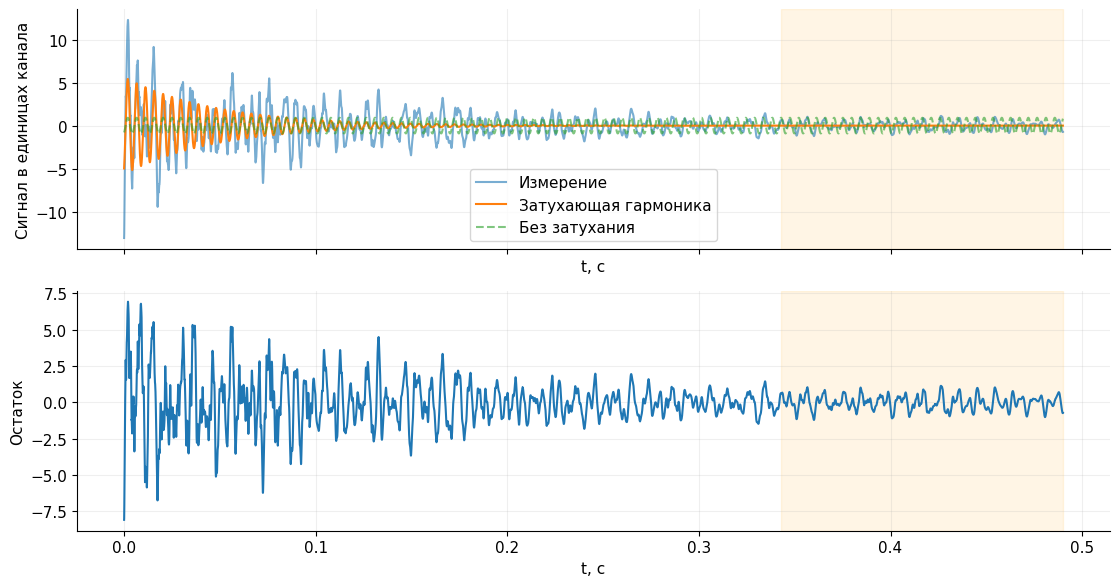

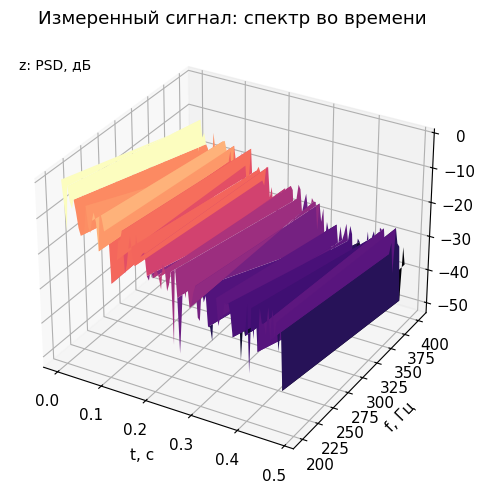

In [18]:
# Заполните по реальному файлу. По умолчанию раздел явно пропускается.
'''
MEMBRANE_CSV = None
MEMBRANE_CSV_OPTIONS = dict(time_column='time', value_columns=['pressure'],
                           delimiter=',', time_scale=1.0)
MEMBRANE_WINDOW = None  # Например (0.05, 0.5) секунд ПОСЛЕ проверки записи.
MEMBRANE_FREQUENCY_BAND = None  # Например (80, 130) Гц; None — оценка по спектру.
'''
MEMBRANE_CSV = MEMBRANE_CSV_PATH
MEMBRANE_CSV_OPTIONS = dict(time_column='time', value_columns=['pressure'], delimiter=',', time_scale=1.0)
MEMBRANE_WINDOW = (0.01, 0.5)   # пропустить сам удар, оставить свободное затухание
MEMBRANE_FREQUENCY_BAND = None  # авто по пику; при необходимости, например (80, 130)
MEMBRANE_GAMMA_MAX = 50      # None — 10 / длительность выбранного участка.
real_membrane = None
if MEMBRANE_CSV is None:
    print('Г1 пропущен: укажите MEMBRANE_CSV и настройки столбцов.')
else:
    ds = read_timeseries_csv(MEMBRANE_CSV, **MEMBRANE_CSV_OPTIONS)
    selected = np.ones(len(ds.time), dtype=bool)
    if MEMBRANE_WINDOW is not None:
        selected = (ds.time >= MEMBRANE_WINDOW[0]) & (ds.time <= MEMBRANE_WINDOW[1])
    rt = ds.time[selected]
    ry = ds.values[selected,0]
    assert len(rt) >= 40, 'Для подбора нужен более длинный участок.'
    rt = rt-rt[0]
    step = np.median(np.diff(rt))
    assert np.max(np.abs(np.diff(rt)-step)) < 0.01*step, 'Спектральная оценка требует равномерной дискретизации.'
    rc = int(0.7*len(rt))
    freq, power = periodogram(ry[:rc], fs=1/step)
    peak = freq[1+np.argmax(power[1:])]
    band = MEMBRANE_FREQUENCY_BAND or (max(1/rt[-1], 0.85*peak), min(0.49/step, 1.15*peak))
    assert 0 < band[0] < band[1] < 0.5/step
    frequency_grid = np.linspace(*band, 100)
    damping_grid = np.linspace(0, MEMBRANE_GAMMA_MAX or 10/rt[-1], 70)
    best_real, best_real_base = np.inf, np.inf
    for frequency in frequency_grid:
        for damping in damping_grid:
            envelope = np.exp(-damping*rt)
            design = np.column_stack((envelope*np.cos(2*np.pi*frequency*rt),
                                      envelope*np.sin(2*np.pi*frequency*rt), np.ones(len(rt))))
            coef = np.linalg.lstsq(design[:rc], ry[:rc], rcond=None)[0]
            pred = design@coef
            error = np.mean((pred[:rc]-ry[:rc])**2)
            if damping == 0 and error < best_real_base:
                best_real_base, base_pred = error, pred.copy()
            if error < best_real:
                best_real, real_pred, real_frequency, real_gamma = error, pred.copy(), frequency, damping
    real_membrane = dict(frequency_hz=real_frequency, gamma_per_s=real_gamma,
                         test_rmse=metrics(ry[rc:], real_pred[rc:])['rmse'])
    display(pd.DataFrame([real_membrane]))
    print('RMSE базовой модели на тесте:', metrics(ry[rc:], base_pred[rc:])['rmse'])
    if real_frequency in (frequency_grid[0], frequency_grid[-1]) or real_gamma == damping_grid[-1]:
        print('Оценка на границе поиска: расширьте сетку и повторите.')
    fig, axes = plt.subplots(2,1,figsize=(12,6),sharex=True)
    axes[0].plot(rt,ry,alpha=0.6,label='Измерение')
    axes[0].plot(rt,real_pred,label='Затухающая гармоника')
    axes[0].plot(rt,base_pred,'--',alpha=0.6,label='Без затухания')
    axes[1].plot(rt,ry-real_pred)
    for ax in axes:
        ax.axvspan(rt[rc],rt[-1],color='orange',alpha=0.1)
        ax.set_xlabel('t, с')
    axes[0].set_ylabel('Сигнал в единицах канала')
    axes[1].set_ylabel('Остаток')
    axes[0].legend()
    for panel in fig.axes:
        if hasattr(panel, "zaxis"):
            zlabel = panel.get_zlabel()
            panel.set_zlabel("")
            panel.text2D(0.02, 0.94, 'z: '+zlabel, transform=panel.transAxes,
                         rotation=0, va="top", fontsize=10)
    plt.tight_layout(rect=(0,0,0.94,1))
    plt.show()
    # 3D-представление измеренного звука: время, частота, спектральная мощность.
    sf, st, power = spectrogram(ry, fs=1/step, nperseg=min(256,len(ry)//4))
    selected_frequency = (sf > 0) & (sf <= min(2.5*real_frequency, 0.5/step))
    if np.count_nonzero(selected_frequency) >= 2 and len(st) >= 2:
        SX, SY = np.meshgrid(st,sf[selected_frequency])
        power_db = 10*np.log10(np.maximum(power[selected_frequency],1e-30)/max(np.max(power),1e-30))
        fig = plt.figure(figsize=(9,5))
        ax = fig.add_subplot(111,projection='3d')
        ax.plot_surface(SX,SY,power_db,cmap='magma')
        ax.set(xlabel='t, с',ylabel='f, Гц',zlabel='PSD, дБ',title='Измеренный сигнал: спектр во времени')
        for panel in fig.axes:
            if hasattr(panel, "zaxis"):
                zlabel = panel.get_zlabel()
                panel.set_zlabel("")
                panel.text2D(0.02, 0.94, 'z: '+zlabel, transform=panel.transAxes,
                             rotation=0, va="top", fontsize=10)
        plt.tight_layout(rect=(0,0,0.94,1))
        plt.show()

### Г2. Температура стержня: теплопроводность и боковая теплоотдача

Используем $\theta_t=\alpha\theta_{xx}-\beta\theta$, $-k\theta_x(0,t)=q_0$, $\theta_x(L,t)=0$, $\theta(x,0)=0$.

Для цилиндра $\alpha=k/(\rho c_p)$, $\beta=4h/(\rho c_p d)$. Температура изначально равномерна. $q_0$ — неизвестный постоянный торцевой поток: подбирается линейно, $\alpha,\beta$ — по сетке. Это упрощение без дополнительной динамики нагревателя. Для определения физического потока нужны известные $\rho,c_p$; оценка $\alpha,\beta$ от их масштаба не зависит при свободной амплитуде потока.

Солвер — конечные объёмы на равномерной сетке и точная во времени эволюция дискретной линейной системы через её собственные моды. Правая часть представляет поток на торце, а не фиктивную фиксированную температуру.


,alpha_m2_s,beta_per_s,k_W_m_K,h_W_m2_K,flux_W_m2,test_rmse
0,0.000033,0.036652,81.110028,72.153737,222393.971844,1.070698


Базовая модель, RMSE теста: 27.12815827945249


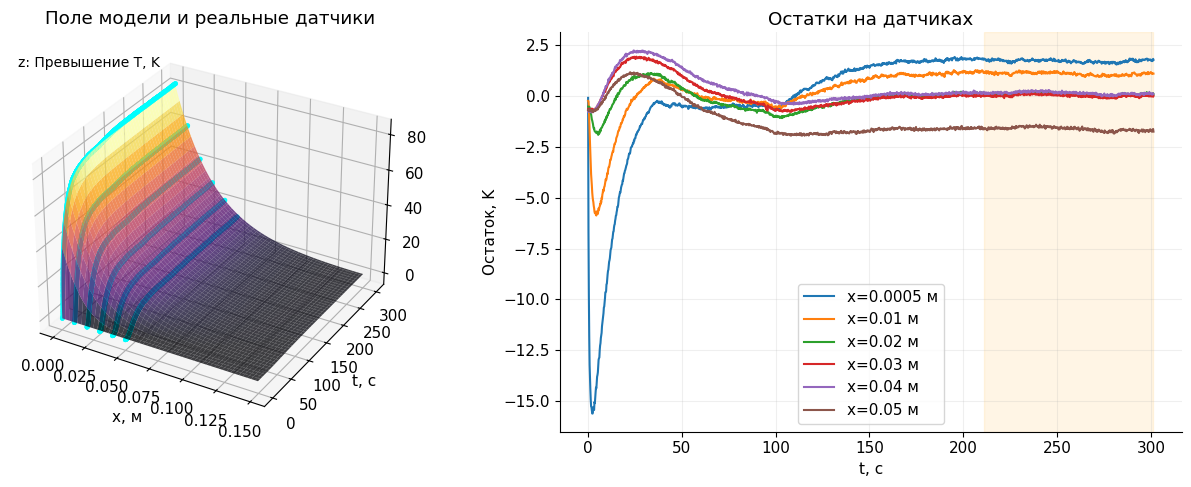

In [23]:
'''
HEAT_CSV = None
HEAT_CSV_OPTIONS = dict(time_column='time', value_columns=['T1','T2'],
                       delimiter=',', time_scale=1.0)
ROD = dict(length_m=None, diameter_m=None, rho_kg_m3=None,
           cp_J_kg_K=None, sensor_x_m=None, ambient_C=None)
# Поисковые интервалы — стартовая настройка, не справочные свойства материала.
ALPHA_RANGE = (1e-6, 2e-4)  # м²/с
BETA_RANGE = (1e-4, 1.0)   # 1/с
ROD_CELLS = 40
'''

HEAT_CSV = Path('sbcf36976g-1/Raw_Data/100al1.csv')
HEAT_CSV_OPTIONS = dict(time_column='Time',
                        value_columns=['TC1','TC2','TC3','TC4','TC5','TC6'],
                        delimiter=',', time_scale=1.0)
ROD_CELLS = 150                       # dx/2 = 0.5 мм
ROD = dict(length_m=0.150, diameter_m=0.003175, rho_kg_m3=2767.99,
           cp_J_kg_K=896,
           # TC1 стоит на нагреваемом торце (x=0); в сеточной модели переносим её в центр первой ячейки
           sensor_x_m=[0.150/ROD_CELLS/2, 0.01, 0.02, 0.03, 0.04, 0.05],
           ambient_C=0.0)             # в CSV уже записано превышение над Tinf≈20.5 °C
# Поисковые интервалы — стартовая настройка, не справочные свойства материала.
ALPHA_RANGE = (1e-6, 2e-4)  # м²/с
BETA_RANGE = (1e-4, 1.0)    # 1/с
ALPHA_POINTS = 80           # было 40: шаг по α ~6% вместо ~15%
HEATER_RATE = None #0.096         # 1/с; нагреватель выходит на мощность как q0(1-exp(-a t)), оценка авторов для 100al1
                            # None — прежняя модель с мгновенным включением потока

def heat_factors(ht, rates, a):
    """Отклик моды с темпом rates на поток q(t)=1 (a=None) или q(t)=1-exp(-a t)."""
    t = ht[:, None]
    out = np.empty((len(ht), len(rates)))
    pos = rates > 0
    r = rates[pos]
    step = -np.expm1(-t*r)/r
    if a is None:
        out[:, pos] = step
        out[:, ~pos] = t
    else:
        r_safe = np.where(np.isclose(r, a), a*(1+1e-6), r)
        out[:, pos] = step - (np.exp(-a*t) - np.exp(-r_safe*t))/(r_safe - a)
        out[:, ~pos] = t + np.expm1(-a*t)/a
    return out

real_heat = None

if HEAT_CSV is None:
    print('Г2 пропущен: укажите HEAT_CSV, геометрию, материал и датчики.')
else:
    assert all(value is not None for value in ROD.values()), 'Заполните все значения ROD из описания опыта.'
    ds = read_timeseries_csv(HEAT_CSV, **HEAT_CSV_OPTIONS)
    ht = ds.time-ds.time[0]
    hy = ds.values-ROD['ambient_C']
    assert len(ht) >= 20 and ht[-1] > 0
    assert np.all(np.abs(hy[0]) < 0.05*np.max(np.abs(hy))), 'Начальное поле не близко к фону: эта постановка неприменима.'
    length, diameter = ROD['length_m'], ROD['diameter_m']
    capacity = ROD['rho_kg_m3']*ROD['cp_J_kg_K']
    assert min(length, diameter, capacity) > 0
    sx = np.asarray(ROD['sensor_x_m'],dtype=float)
    assert len(sx) == hy.shape[1]
    dx = length/ROD_CELLS
    centers = (np.arange(ROD_CELLS)+0.5)*dx
    assert np.all((sx >= centers[0]) & (sx <= centers[-1])), 'Датчики должны попадать между центрами крайних ячеек; увеличьте ROD_CELLS при необходимости.'
    diagonal = np.full(ROD_CELLS, 2.0)
    diagonal[[0,-1]] = 1.0
    eigen, vectors = eigh_tridiagonal(diagonal/dx**2, -np.ones(ROD_CELLS-1)/dx**2)
    eigen = np.maximum(eigen,0)
    eigen[0] = 0  # Постоянная мода при двух условиях Неймана.
    # Источник на первой ячейке при единичном потоке W/m².
    excitation = vectors[0,:]/(capacity*dx)
    interpolation = np.empty((len(sx), ROD_CELLS))
    for j in range(ROD_CELLS):
        interpolation[:,j] = np.interp(sx, centers, vectors[:,j])
    hc = int(0.7*len(ht))
    alpha_grid = np.geomspace(*ALPHA_RANGE, ALPHA_POINTS)
    beta_grid = np.r_[0, np.geomspace(*BETA_RANGE, 40)]
    best_h, best_h_base = np.inf, np.inf
    for alpha in alpha_grid:
        for beta in beta_grid:
            '''
            rates = alpha*eigen+beta
            factors = np.empty((len(ht), ROD_CELLS))
            positive = rates > 0
            factors[:,positive] = -np.expm1(-ht[:,None]*rates[positive])/rates[positive]
            factors[:,~positive] = ht[:,None]
            '''
            factors = heat_factors(ht, alpha*eigen+beta, HEATER_RATE)

            response = (factors*excitation)@interpolation.T
            denom = np.sum(response[:hc]**2)
            flux = np.sum(response[:hc]*hy[:hc])/denom
            if flux < 0:
                continue
            pred = flux*response
            error = np.mean((pred[:hc]-hy[:hc])**2)
            if beta == 0 and error < best_h_base:
                best_h_base, heat_base = error, pred.copy()
            if error < best_h:
                best_h, heat_prediction = error, pred.copy()
                best_alpha, best_beta, best_flux = alpha, beta, flux
    assert np.isfinite(best_h), 'Проверьте знак нагрева, фон и диапазоны параметров.'
    real_heat = dict(alpha_m2_s=best_alpha, beta_per_s=best_beta,
        k_W_m_K=best_alpha*capacity, h_W_m2_K=best_beta*capacity*diameter/4,
        flux_W_m2=best_flux, test_rmse=metrics(hy[hc:],heat_prediction[hc:])['rmse'])
    display(pd.DataFrame([real_heat]))
    print('Базовая модель, RMSE теста:', metrics(hy[hc:],heat_base[hc:])['rmse'])
    if best_alpha in (alpha_grid[0],alpha_grid[-1]) or best_beta == beta_grid[-1]:
        print('Оптимум на границе поиска: уточните диапазоны.')
    #rates = best_alpha*eigen+best_beta
    #factors = np.empty((len(ht),ROD_CELLS))
    #positive = rates > 0
    #factors[:,positive] = -np.expm1(-ht[:,None]*rates[positive])/rates[positive]
    #factors[:,~positive] = ht[:,None]
    factors = heat_factors(ht, best_alpha*eigen+best_beta, HEATER_RATE)

    heat_field = best_flux*(factors*excitation)@vectors.T
    HX, HT = np.meshgrid(centers,ht)
    fig = plt.figure(figsize=(14,5))
    ax = fig.add_subplot(1,2,1,projection='3d')
    ax.plot_surface(HX,HT,heat_field,cmap='inferno',alpha=0.75)
    for j,x in enumerate(sx):
        ax.scatter(np.full(len(ht),x),ht,hy[:,j],s=6,color='cyan')
    ax.set(xlabel='x, м',ylabel='t, с',zlabel='Превышение T, K',title='Поле модели и реальные датчики')
    ax = fig.add_subplot(1,2,2)
    for j,x in enumerate(sx):
        ax.plot(ht,hy[:,j]-heat_prediction[:,j],label=f'x={x:g} м')
    ax.axvspan(ht[hc],ht[-1],color='orange',alpha=0.1)
    ax.set(xlabel='t, с',ylabel='Остаток, K',title='Остатки на датчиках')
    ax.legend()
    for panel in fig.axes:
        if hasattr(panel, "zaxis"):
            zlabel = panel.get_zlabel()
            panel.set_zlabel("")
            panel.text2D(0.02, 0.94, 'z: '+zlabel, transform=panel.transAxes,
                         rotation=0, va="top", fontsize=10)
    plt.tight_layout(rect=(0,0,0.94,1))
    plt.show()

## Проверка модулей

Тесты проверяют аналитические решения, нулевые границы, монотонность энергии/нормы, восстановление параметров и загрузчик с поддельным HTTP-ответом. Они не проверяют физическую применимость модели к конкретному реальному опыту.

In [18]:
required_tests = [Path('test_models.py'), Path('test_data_io.py')]
if all(path.exists() for path in required_tests):
    suite = unittest.defaultTestLoader.discover('.', pattern='test_*.py')
    test_result = unittest.TextTestRunner(verbosity=1).run(suite)
    assert test_result.wasSuccessful(), 'Исправьте ошибки тестов перед интерпретацией результатов.'
else:
    print('Файлы тестов отсутствуют. Поместите test_models.py и test_data_io.py рядом с ноутбуком.')

..........
----------------------------------------------------------------------
Ran 10 tests in 0.369s

OK
